# L34 - Burg-Algorithmus (Lösung zu Aufgabe 34)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken (`l34.m`)](./l34.m).

Weitere benötigne MATLAB `*.m`-Dateien:  [`lburg_algo.m`](./lburg_algo.m)

In [3]:
MA = 1; 
AR = [1.0000 0.3611 -0.1373 0.2685 -0.0533 -0.3353 -0.307];
NFFT=2^10;

## Teilaufgabe a:  AR-System, Einschwingverhalten

exakte AKF (eingeschw. Zustand)

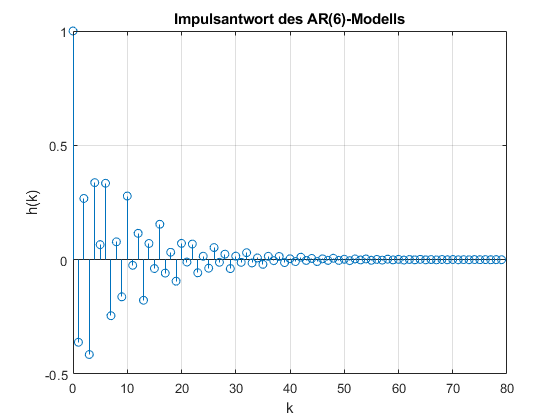

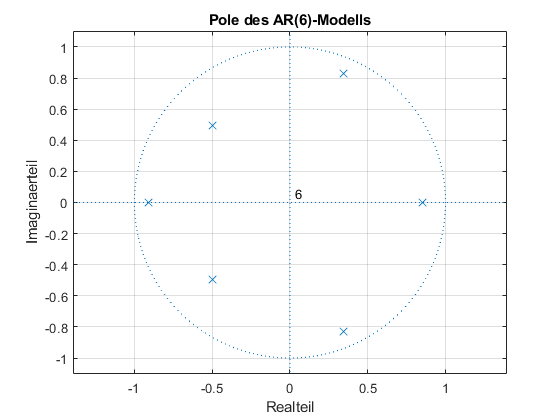

In [4]:
[h_arma,t] = impz(MA,AR,80);

% # grafische Ausgabe # %
figure;
stem(t,h_arma); 
grid; 
xlabel('k'); 
ylabel('h(k)');
title(sprintf('Impulsantwort des AR(%d)-Modells',length(AR)-1));

figure; 
[h1,h2,h3]=zplane(MA,AR); set(h1,'Visible','off');
title(sprintf('Pole des AR(%d)-Modells',length(AR)-1)); 
grid;
xlabel('Realteil'); 
ylabel('Imaginaerteil');

##  Teilaufgabe b:  AR-System, LDS

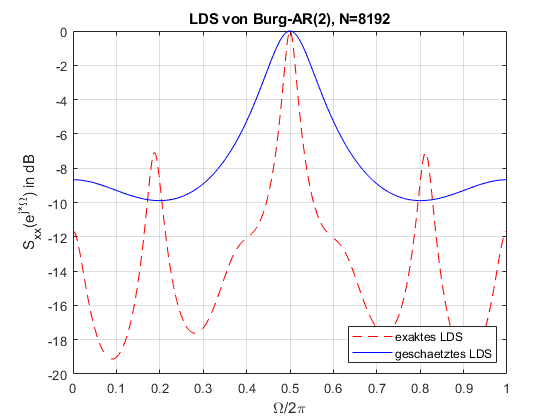

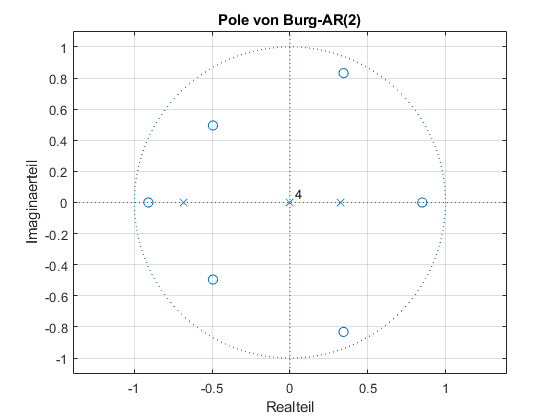

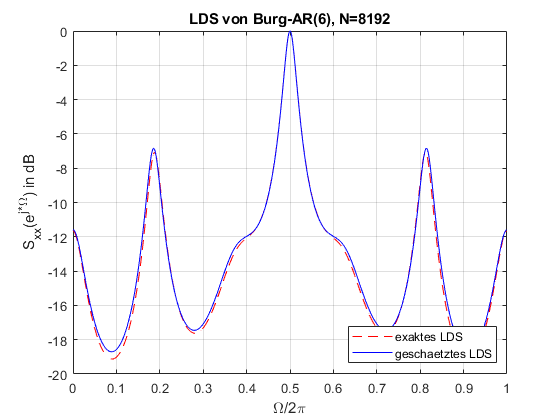

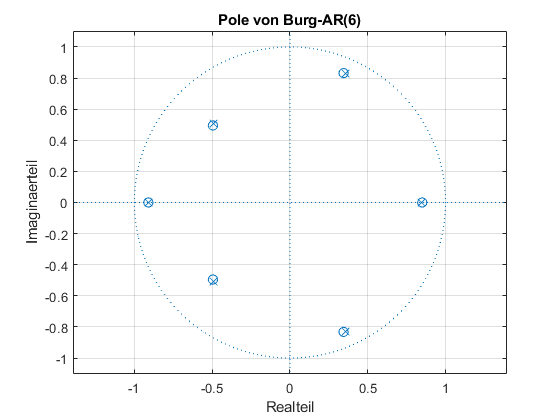

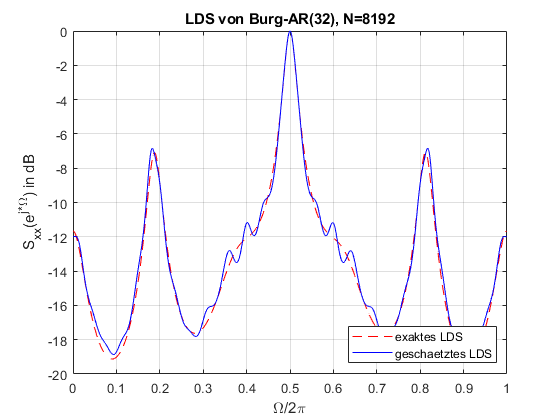

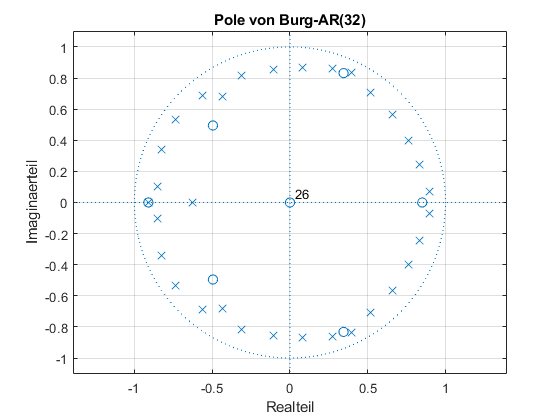

In [5]:
% Analyse der Filterordnung AR(n)
Omega_norm = 0:1/NFFT:1-1/NFFT;
Sxx_arma = abs(fft(MA,NFFT)./fft(AR,NFFT)).^2;
n = [2 length(AR)-1 32];
N = 2^13;
N_vor = 80;
Noise = randn(1,N+N_vor);
x_all = filter(MA,AR,Noise);
x = x_all(N_vor+1:length(x_all));

for k = 1:3
    ar = lburg_algo(x,N,n(k),MA,AR);
    Sxx_ar = abs(ones(1,NFFT)./fft(ar,NFFT)).^2;
    Sxx_ar = Sxx_ar/sum(Sxx_ar).*sum(Sxx_arma);
    % # grafische Ausgabe # %
    figure;
    h1 = plot(Omega_norm, 10*log10(Sxx_arma/max(Sxx_arma)),'r--');  
    hold on;
    h2 = plot(Omega_norm, 10*log10(Sxx_ar/max(Sxx_ar)),'b-');
    ylabel('S_{xx}(e^{j*\Omega}) in dB');
    title(sprintf('LDS von Burg-AR(%d), N=%d', n(k),N)); 
    xlabel('\Omega/2\pi'); 
    grid;
    legend([h1(1),h2(1)],'exaktes LDS','geschaetztes LDS','Location','Southeast');
    
    figure; 
    zplane(AR,ar); 
    title(sprintf('Pole von Burg-AR(%d)',n(k)));
    xlabel('Realteil'); 
    ylabel('Imaginaerteil'); 
    grid;
end

##  Teilaufgabe c:  MA-System

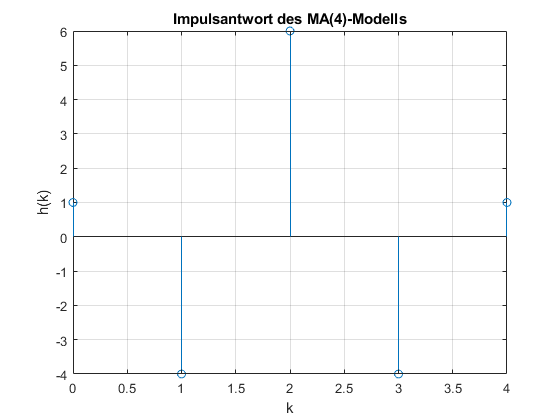

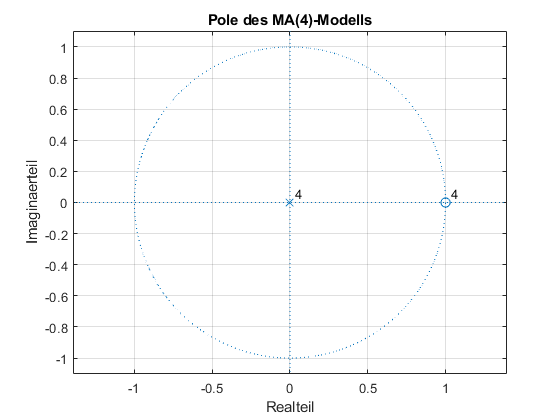

In [7]:
% Analyse der Filterordnung AR(n)
MA = [1 -4 6 -4 1]; 
AR = 1;

% Einschwingverhalten
[h_arma,t] = impz(MA,AR);

% # grafische Ausgabe # %
figure; 
stem(t,h_arma); 
grid; 
xlabel('k'); 
ylabel('h(k)');
title(sprintf('Impulsantwort des MA(%d)-Modells',length(MA)-1));

figure; 
zplane(MA,AR);
title(sprintf('Pole des MA(%d)-Modells',length(MA)-1));
xlabel('Realteil'); 
ylabel('Imaginaerteil'); 
grid;



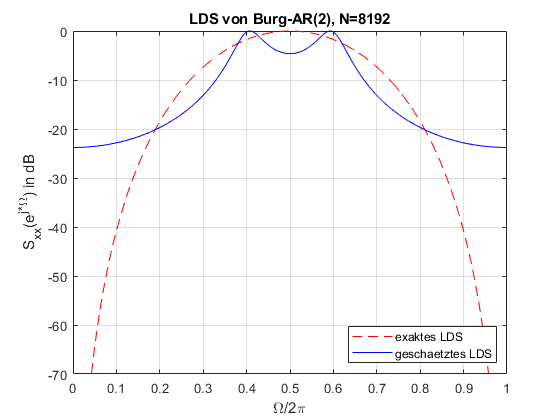

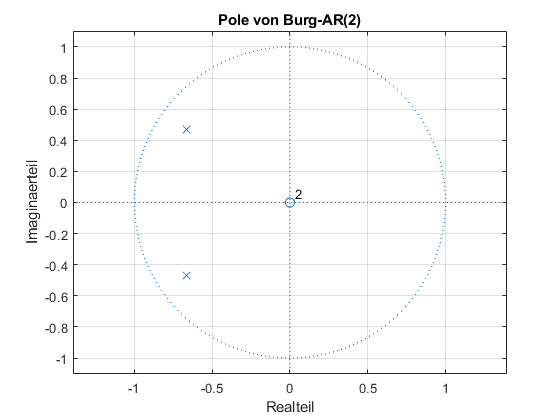

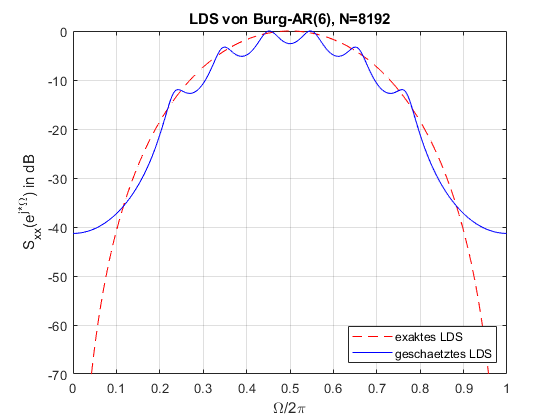

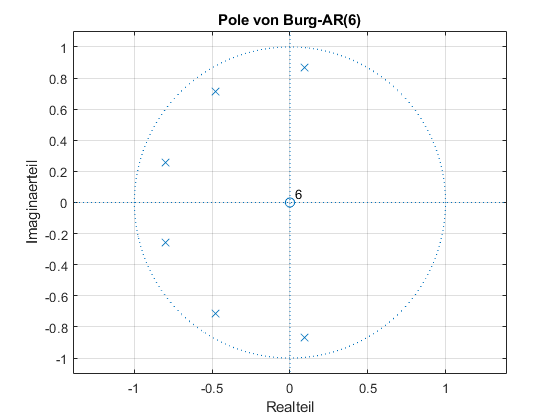

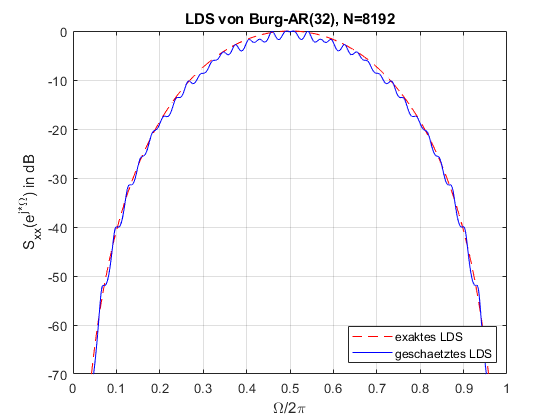

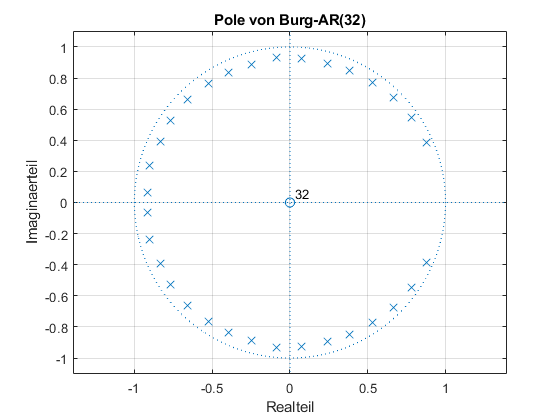

In [8]:
% Analyse der Filterordnung AR(n), LDS
Omega_norm  = 0:1/NFFT:1-1/NFFT;
Sxx_arma = abs(fft(MA,NFFT)./fft(AR,NFFT)).^2;

n = [2 6 32];
N = 2^13;
N_vor = 5;
noise = randn(1,N+N_vor);
x_all = filter(MA,AR,noise);
x = x_all(N_vor+1:length(x_all));

for k = 1:3
    ar = lburg_algo(x,N,n(k),MA,AR);
    Sxx_ar = abs(ones(1,NFFT)./fft(ar,NFFT)).^2;
    Sxx_ar = Sxx_ar/sum(Sxx_ar).*sum(Sxx_arma);
    
    % # grafische Ausgabe # %
    figure;
    Sxx_ar(Sxx_ar==0) = 1e-10;
    Sxx_arma(Sxx_arma==0) = 1e-10;
    h1 = plot(Omega_norm, 10*log10(Sxx_arma/max(Sxx_arma)),'r--');  
    hold on;
    h2 = plot(Omega_norm, 10*log10(Sxx_ar/max(Sxx_ar)),'b-');
    xlabel('\Omega/2\pi'); 
    ylabel('S_{xx}(e^{j*\Omega}) in dB');
    title(sprintf('LDS von Burg-AR(%d), N=%d', n(k),N)); 
    grid;
    legend([h1(1),h2(1)],'exaktes LDS','geschaetztes LDS','Location','Southeast');
    axis([0 1 -70 0]);
    
    figure; 
    zplane(AR,ar); 
    title(sprintf('Pole von Burg-AR(%d)',n(k)));
    xlabel('Realteil'); 
    ylabel('Imaginaerteil'); 
    grid;
end